<a href="https://colab.research.google.com/github/sisco-velasquez/machine_learning/blob/main/regression_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
import random
import os
import time

def guess_game():
    try:
        difficulty = int(input("Enter the difficulty level 1. easy, 2. medium, 3. hard: "))
    except ValueError:
        print("Please enter a valid number.")
        return

    match difficulty:
        case 1:
            attempts = 10
        case 2:
            attempts = 7
        case 3:
            attempts = 5
        case _:
            print("Invalid difficulty level")
            return

    print(f"You have {attempts} attempts to guess the number")

    random_number = random.randint(1, 100)
    while attempts > 0:
        try:
            guess = int(input("Guess the number: "))
        except ValueError:
            print("Please enter a valid integer.")
            continue

        match guess:
            case _ if guess == random_number:
                print("You guessed the correct number!")
                return
            case _ if guess > random_number:
                print("Your guess is too high")
                attempts -= 1
            case _ if guess < random_number:
                print("Your guess is too low")
                attempts -= 1
        if attempts > 0:
            print(f"Remaining attempts: {attempts}")

    print(f"Game over! The correct number was {random_number}.")

# Main execution loop (indented correctly outside the function)
while True:
    guess_game()
    play_again = input("Do you want to play again? (y/n): ")
    if play_again.lower() != "y":
        break
    time.sleep(1)

Enter the difficulty level 1. easy, 2. medium, 3. hard: 2
You have 7 attempts to guess the number
Guess the number: 10
Your guess is too low
Remaining attempts: 6
Guess the number: 45
Your guess is too low
Remaining attempts: 5
Guess the number: 76
Your guess is too low
Remaining attempts: 4
Guess the number: 98
Your guess is too high
Remaining attempts: 3
Guess the number: 87
Your guess is too low
Remaining attempts: 2
Guess the number: 90
Your guess is too low
Remaining attempts: 1
Guess the number: 93
Your guess is too low
Game over! The correct number was 95.
Do you want to play again? (y/n): y
Enter the difficulty level 1. easy, 2. medium, 3. hard: 6
Invalid difficulty level
Do you want to play again? (y/n): y
Enter the difficulty level 1. easy, 2. medium, 3. hard: 2
You have 7 attempts to guess the number
Guess the number: 67
Your guess is too high
Remaining attempts: 6
Guess the number: 45
Your guess is too high
Remaining attempts: 5
Guess the number: 23
Your guess is too high
R

The best line is: y = 0.70x + 1.90


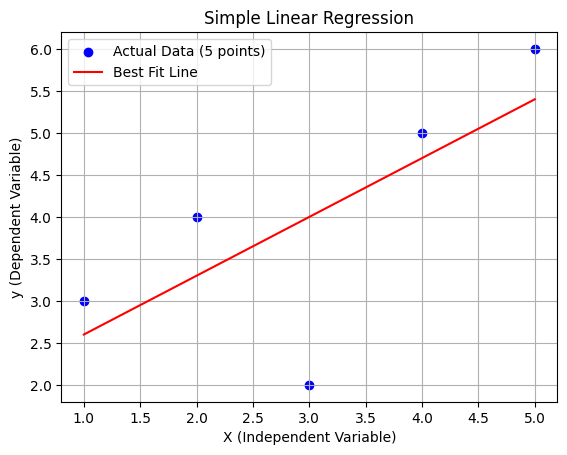

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# 1. Provide the data (5 rows)
# X represents the independent variable (e.g., Hours Studied)
# y represents the dependent variable (e.g., Test Score)
X = np.array([[1], [2], [3], [4], [5]])
y = np.array([3, 4, 2, 5, 6])

# 2. Create and train the model
model = LinearRegression()
model.fit(X, y) # This is where the OLS math happens

# 3. Get the "best fit" line details
slope = model.coef_[0]
intercept = model.intercept_

print(f"The best line is: y = {slope:.2f}x + {intercept:.2f}")

# 4. Make predictions using the best line
predictions = model.predict(X)

# 5. Visualize the data and the line
plt.scatter(X, y, color='blue', label='Actual Data (5 points)')
plt.plot(X, predictions, color='red', label='Best Fit Line')

plt.title('Simple Linear Regression')
plt.xlabel('X (Independent Variable)')
plt.ylabel('y (Dependent Variable)')
plt.legend()
plt.grid(True)
plt.show()

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score


#load data

companies = pd.read_csv('/content/1000_Companies.csv')
x = companies.iloc[:, : -1].values
y = companies.iloc[:,  4].values
companies.head()






,R&D Spend,Administration,Marketing Spend,State,Profit
0,165349.20,136897.80,471784.10,New York,192261.83
1,162597.70,151377.59,443898.53,California,191792.06
2,153441.51,101145.55,407934.54,Florida,191050.39
3,144372.41,118671.85,383199.62,New York,182901.99
4,142107.34,91391.77,366168.42,Florida,166187.94


<Axes: >

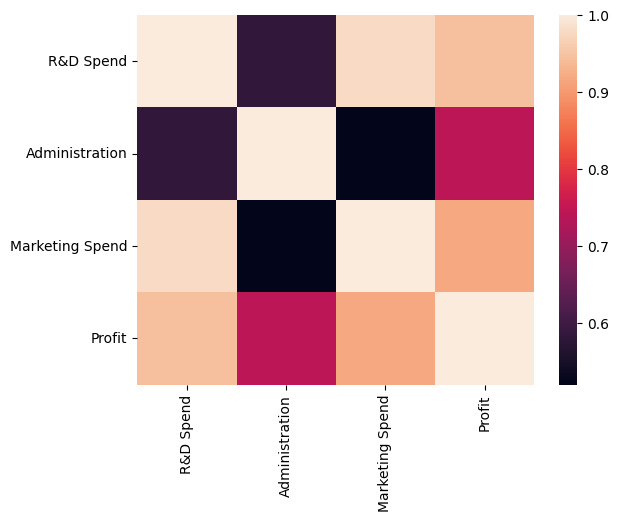

In [3]:
companies = pd.read_csv('/content/1000_Companies.csv')
x = companies.iloc[:, : -1].values
y = companies.iloc[:,  4].values
companies.head()

sns.heatmap(companies.corr(numeric_only= True))

###### encoding categorical data

In [10]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

labelencoder = LabelEncoder()
x[:, 3] = labelencoder.fit_transform(x[:, 3])
# transform = make_column_transformer((OneHotEncoder(), x[:, 3]), remainder = 'passthrough')

onehotencoder = OneHotEncoder()
enc_data = onehotencoder.fit_transform(x[:, 3].reshape(-1,1)).toarray()


######Avoiding dummy variable trap

In [12]:
x = x[:, 1:]

#####Splitting the data into train and test set

In [13]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 0)

######Fitting the Multiple Linear Regression Model to Training Set

In [14]:
from sklearn.linear_model import LinearRegression
regressor = LinearRegression()
regressor.fit(x_train, y_train)

LinearRegression()

In [15]:
y_pred = regressor.predict(x_test)
y_pred

array([ 90209.64901318,  88876.28325862,  95200.74973042, 174739.58503941,
        84013.74722284, 110572.81423949, 169438.58451208,  91855.1682484 ,
       163402.29005648,  54991.76617392,  67874.72481309, 150180.9861358 ,
       126512.60670878,  60430.86889281, 175991.46628657,  76097.46542299,
       118577.95366564, 163338.33779446, 165329.70854714, 180487.66382609,
       101238.40282718,  86180.18269683, 179933.75346041,  84689.06190888,
       105088.13051962, 101399.34780971,  40828.42858138,  58070.59626831,
        69777.85472814, 226802.72627013, 121052.52594777, 111658.45981284,
       101689.86321283, 137852.59801618,  64960.45224275, 108854.95146996,
       184345.94907957, 170595.15880734, 173725.92497117, 118014.06326024,
        97038.60706862, 164196.76013804, 107746.47058118,  52030.50278345,
       116882.08703837,  59741.11018494, 157857.27897357,  79750.07622713,
       159139.45816291, 131182.41311202, 183735.81760226, 173691.52102156,
        94077.16471212,  

In [16]:
#caliculating the coefficient
print(regressor.coef_)

[   1.04239904    0.35510511 -320.45531609]


In [17]:
#caliculating the intercept
print(regressor.intercept_)

-88623.76527343772


In [18]:
from sklearn.metrics import r2_score
r2_score(y_test, y_pred)

0.8985038788872521